## Regression Project Machine Learning 2
#### Izabela Kosiec (441755)
#### Katarzyna Pełka (432453)

### Introduction

In recent years, short-term rental platforms such as Airbnb have generated large and complex datasets that reflect interactions between location, property characteristics, host behavior, and market demand. These datasets provide an opportunity to study pricing mechanisms in urban environments, where prices are shaped by both observable listing attributes and latent spatial and economic factors.

The objective of this project is to predict nightly prices of Airbnb listings in New York City using a regression-based machine learning approach. Pricing in the short-term rental market is a challenging task due to the highly skewed distribution of prices, strong nonlinear effects, and substantial heterogeneity across neighborhoods and property types. From a methodological perspective, this problem allows for the evaluation of different regression models under realistic conditions, including heavy-tailed targets, correlated features, and noisy observations.

This topic was selected to move beyond simple linear pricing models and to assess how modern tree-based ensemble methods perform when modeling complex, nonlinear relationships in real-world housing and tourism data. In particular, the project focuses on comparing classical regression techniques with bagging- and boosting-based machine learning models, while carefully addressing issues of overfitting, model interpretability, and generalization performance.

### Data description

The dataset used in this project originates from Kaggle and contains detailed information on Airbnb listings located in New York City. It includes a wide range of variables describing property characteristics, host activity, location, availability, and user feedback. The dataset represents a large and heterogeneous urban rental market, with listings differing substantially in price, size, and amenities.

The target variable is the nightly listing price expressed in USD. An exploratory analysis revealed that the price distribution is highly right-skewed, with a small number of extremely expensive listings. To address this issue and improve model stability, a logarithmic transformation of the target variable was applied. Models were trained using the log-transformed price, while evaluation metrics were reported in the original price scale to preserve interpretability.

The feature set consists of both numeric variables (such as number of reviews, availability, geographic coordinates, and derived rating measures) and categorical variables (including room type and neighborhood group). Several identifier-like and high-cardinality text features were removed during preprocessing, as they do not provide meaningful predictive information for the pricing task.

Overall, the dataset is well-suited for a regression problem but presents multiple challenges typical of real-world pricing data, including nonlinear relationships, spatial effects, correlated features, and the presence of outliers. These characteristics make it an appropriate benchmark for evaluating modern machine learning regression models under realistic conditions.

In [1]:
import warnings

warnings.filterwarnings(
    "ignore",
    category=FutureWarning,
    module="seaborn"
)

In [2]:
# imports
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor,VotingRegressor

# Reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

# Plot style
sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

C:\Users\48661\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


In [3]:
# Loading dataset
data_path = "new_york_listings_2024.csv"
df_raw = pd.read_csv(data_path)

# Make a working copy
df = df_raw.copy()

print("Data shape:", df.shape)


Data shape: (20758, 22)


In [4]:
print("\nColumns:", df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())


Columns: ['id', 'name', 'host_id', 'host_name', 'neighbourhood_group', 'neighbourhood', 'latitude', 'longitude', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'last_review', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365', 'number_of_reviews_ltm', 'license', 'rating', 'bedrooms', 'beds', 'baths']

First 5 rows:


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,...,last_review,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm,license,rating,bedrooms,beds,baths
0,1312228,Rental unit in Brooklyn · ★5.0 · 1 bedroom,7130382,Walter,Brooklyn,Clinton Hill,40.683710,-73.964610,Private room,55.0,...,2015-12-20,0.03,1,0,0,No License,5.0,1,1,Not specified
1,45277537,Rental unit in New York · ★4.67 · 2 bedrooms ·...,51501835,Jeniffer,Manhattan,Hell's Kitchen,40.766610,-73.988100,Entire home/apt,144.0,...,2023-05-01,0.24,139,364,2,No License,4.67,2,1,1
2,971353993633883038,Rental unit in New York · ★4.17 · 1 bedroom · ...,528871354,Joshua,Manhattan,Chelsea,40.750764,-73.994605,Entire home/apt,187.0,...,2023-12-18,1.67,1,343,6,Exempt,4.17,1,2,1
3,3857863,Rental unit in New York · ★4.64 · 1 bedroom · ...,19902271,John And Catherine,Manhattan,Washington Heights,40.835600,-73.942500,Private room,120.0,...,2023-09-17,1.38,2,363,12,No License,4.64,1,1,1
4,40896611,Condo in New York · ★4.91 · Studio · 1 bed · 1...,61391963,Stay With Vibe,Manhattan,Murray Hill,40.751120,-73.978600,Entire home/apt,85.0,...,2023-12-03,0.24,133,335,3,No License,4.91,Studio,1,1


The dataset `new_york_listings_2024.csv` contains 20 758 observations and 22 columns
describing property characteristics, host activity, location, availability, and user feedback.

Examples of variables:
- **latitude, longitude**– geographic coordinates of the listing, capturing spatial effects within the city

- **neighbourhood_group**– high-level administrative area of New York City (categorical)

- **neighbourhood** – local neighborhood name (categorical)

- **room_type** – type of accommodation offered (Entire home/apt, Private room, Shared room)

- **bedrooms, beds, baths** – indicators of property size and capacity

- **minimum_nights** – minimum required length of stay

- **availability_365** – number of available days in a year, reflecting booking intensity

- **number_of_reviews, number_of_reviews_ltm, reviews_per_month** – measures of listing popularity and activity

- **rating** – average user rating of the listing

- **calculated_host_listings_count** – number of listings managed by the same host

- **license** – regulatory status of the listing (categorical)
- **price** - target variable

In [5]:
# Basic informations about columns and types
print("Dataset info:")
print(df.info())

# Checking missing values
print("\nMissing values per column:")
print(df.isna().sum())

Dataset info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20758 entries, 0 to 20757
Data columns (total 22 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              20758 non-null  int64  
 1   name                            20758 non-null  object 
 2   host_id                         20758 non-null  int64  
 3   host_name                       20758 non-null  object 
 4   neighbourhood_group             20758 non-null  object 
 5   neighbourhood                   20758 non-null  object 
 6   latitude                        20758 non-null  float64
 7   longitude                       20758 non-null  float64
 8   room_type                       20758 non-null  object 
 9   price                           20758 non-null  float64
 10  minimum_nights                  20758 non-null  int64  
 11  number_of_reviews               20758 non-null  int64  
 12  last_review       

### Data cleaning and preparation

In [6]:
# Summary statistics for the target variable 'price'
print("\nSummary statistics for price:")
print(df["price"].describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]))


Summary statistics for price:
count     20758.000000
mean        187.776616
std        1022.797208
min          10.000000
50%         125.000000
75%         199.000000
90%         309.000000
95%         430.000000
99%         999.000000
max      100000.000000
Name: price, dtype: float64


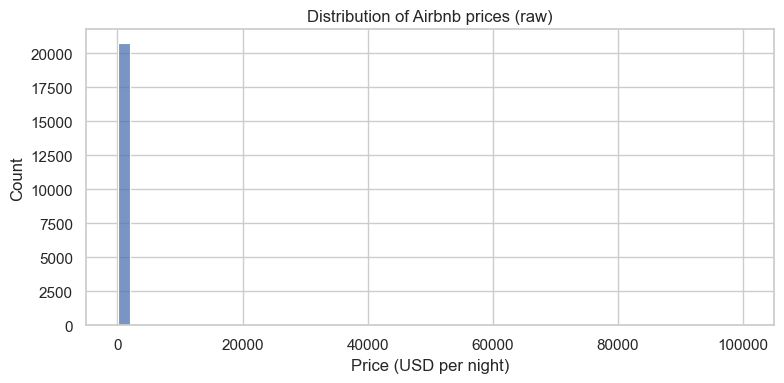

In [7]:
# Histogram of price 
plt.figure(figsize=(8, 4))
sns.histplot(df["price"], bins=50, kde=False)
plt.title("Distribution of Airbnb prices (raw)")
plt.xlabel("Price (USD per night)")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

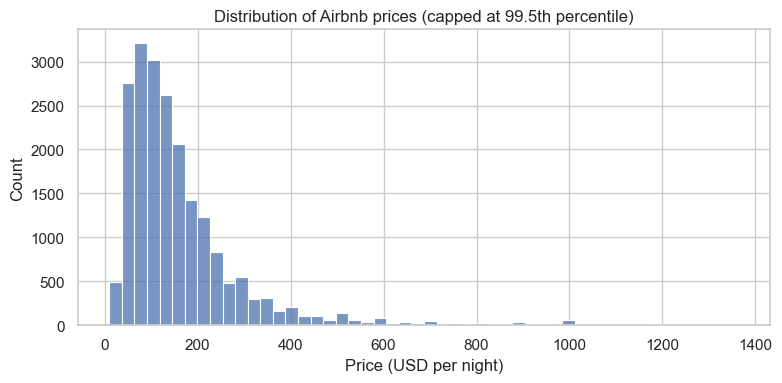

In [8]:
# Because price has very heavy tail (few very expensive listings),
# it was useful to also visualize a restricted range (up to the 99.5th percentile).
price_cap = df["price"].quantile(0.995)

plt.figure(figsize=(8, 4))
sns.histplot(df[df["price"] <= price_cap]["price"], bins=50, kde=False)
plt.title("Distribution of Airbnb prices (capped at 99.5th percentile)")
plt.xlabel("Price (USD per night)")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

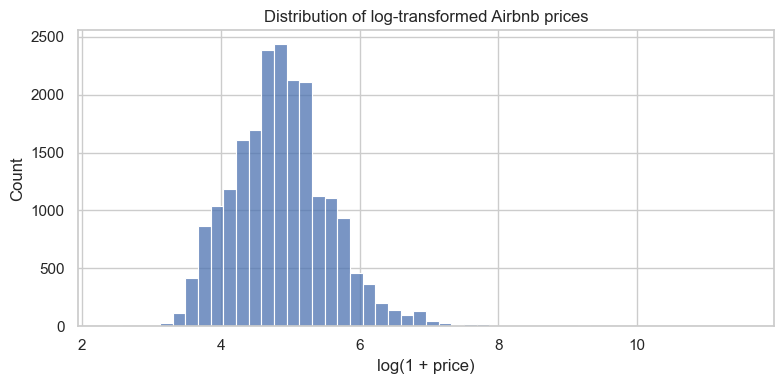

count    20758.000000
mean         4.875430
std          0.710921
min          2.397895
25%          4.394449
50%          4.836282
75%          5.298317
max         11.512935
Name: price_log, dtype: float64


In [9]:
# Log-transformed price distribution

df["price_log"] = np.log1p(df["price"])

plt.figure(figsize=(8, 4))
sns.histplot(df["price_log"], bins=50, kde=False)
plt.title("Distribution of log-transformed Airbnb prices")
plt.xlabel("log(1 + price)")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

print(df["price_log"].describe())


The price distribution is highly right-skewed, even after trimming extreme outliers. Therefore, in the modeling stage, we additionally consider a log-transformation of the target variable to stabilize variance and reduce the influence of extreme prices.

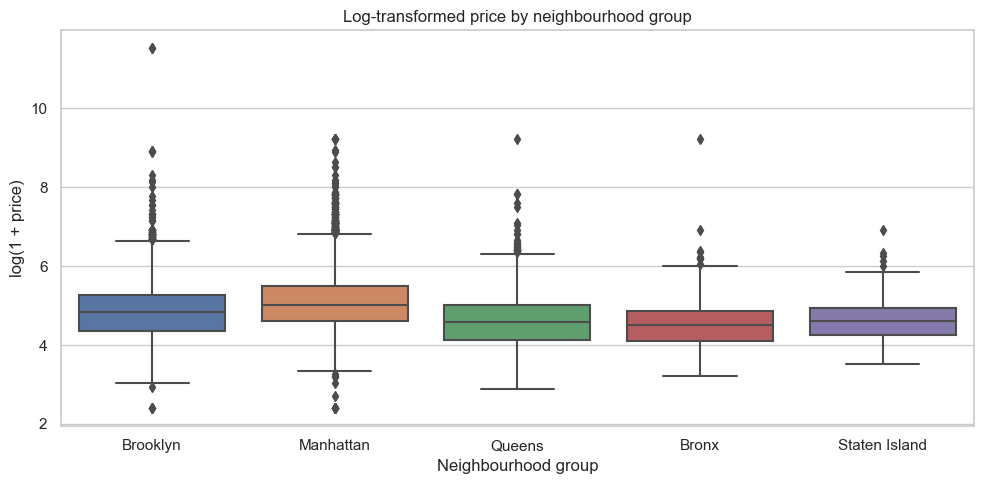

In [10]:
## Looking for any irregularities we decided to check price distribution based on the neighbourhood group 
plt.figure(figsize=(10, 5))
sns.boxplot(
    data=df,
    x="neighbourhood_group",
    y="price_log"
)
plt.title("Log-transformed price by neighbourhood group")
plt.xlabel("Neighbourhood group")
plt.ylabel("log(1 + price)")
plt.tight_layout()
plt.show()


In [11]:
#Even after log-transformation, the top 0.5% of listings exhibited extreme behavior; therefore, they were removed to improve model stability
price_cap = df["price_log"].quantile(0.995)
df = df[df["price_log"] <= price_cap].copy()

print("\nShape after removing top 0.5 percent most expensive listings:", df.shape)


Shape after removing top 0.5 percent most expensive listings: (20654, 23)


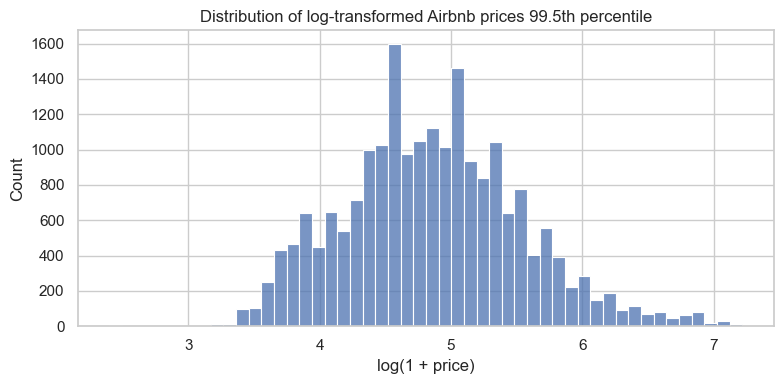

In [12]:
# Log-transformed price distribution (99.5th percentile)

plt.figure(figsize=(8, 4))
sns.histplot(df["price_log"], bins=50, kde=False)
plt.title("Distribution of log-transformed Airbnb prices 99.5th percentile")
plt.xlabel("log(1 + price)")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

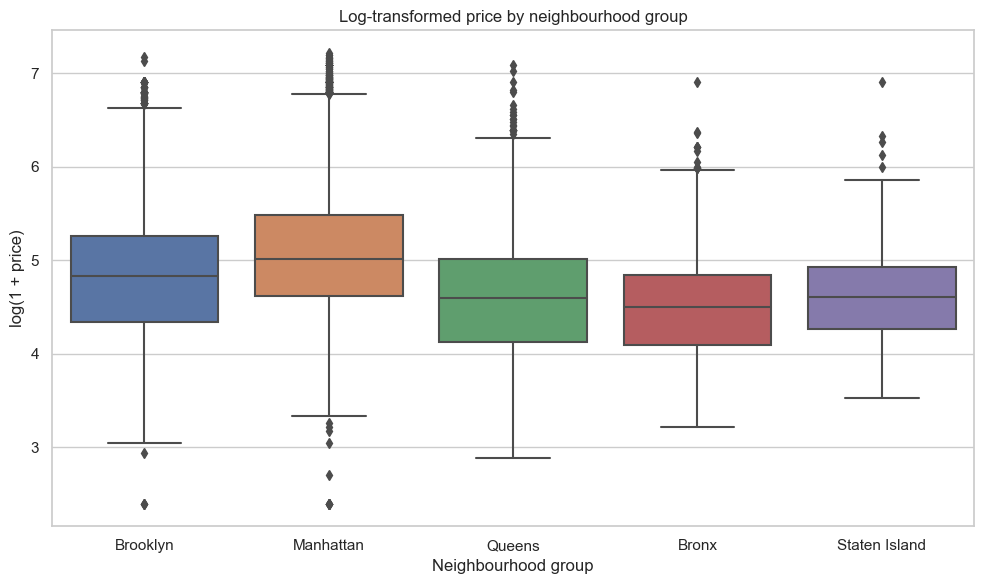

In [13]:
## Price distribution based on the neighbourhood group check after trimming the data
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=df,
    x="neighbourhood_group",
    y="price_log"
)
plt.title("Log-transformed price by neighbourhood group")
plt.xlabel("Neighbourhood group")
plt.ylabel("log(1 + price)")
plt.tight_layout()
plt.show()


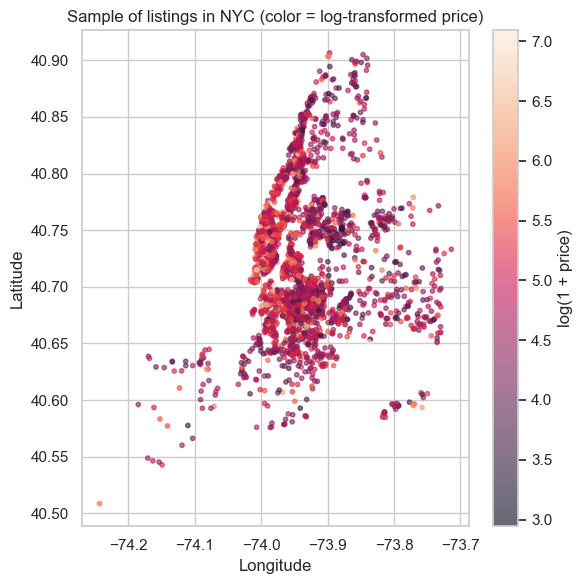

In [14]:
# Scatter plot: location vs log-price 
sample_for_plot = df.sample(n=3000, random_state=RANDOM_STATE)

plt.figure(figsize=(6, 6))
sc = plt.scatter(
    sample_for_plot["longitude"],
    sample_for_plot["latitude"],
    c=sample_for_plot["price_log"],
    s=10,
    alpha=0.6
)

plt.colorbar(sc, label="log(1 + price)")
plt.title("Sample of listings in NYC (color = log-transformed price)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.tight_layout()
plt.show()


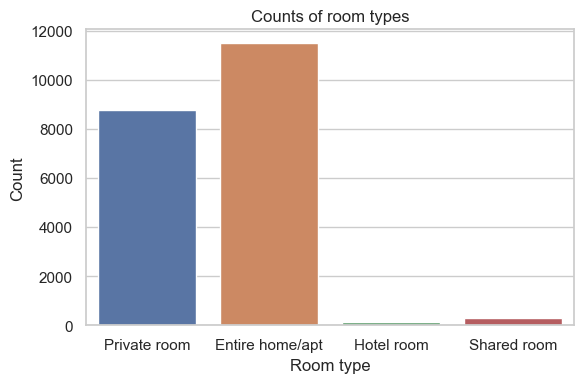

In [15]:
# Countplot for room_type
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="room_type")
plt.title("Counts of room types")
plt.xlabel("Room type")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

In [16]:
# Creating a numeric rating variable
# We convert strings like "5.0", "4.67" to numeric and treat "No rating" / "New" as missing (NaN -> 0 later).

rating_clean = df["rating"].astype(str).str.strip()
# Replacing known non-numeric labels with NaN
rating_clean = rating_clean.replace({
    "No rating": np.nan,
    "New": np.nan,
    "New ": np.nan   })

# Converting to numeric, anything non-numeric becomes NaN
df["rating_numeric"] = pd.to_numeric(rating_clean, errors="coerce")

# Filling missing ratings with 0 (meaning: no rating yet)
df["rating_numeric"].fillna(0.0, inplace=True)

print(df["rating"].value_counts().head(10))
print(df["rating_numeric"].describe())


rating
No rating    3568
5.0          2853
4.67          516
4.75          468
4.80          438
4.83          424
4.88          423
4.86          419
4.89          376
4.92          367
Name: count, dtype: int64
count    20654.000000
mean         3.879895
std          1.839998
min          0.000000
25%          4.330000
50%          4.750000
75%          4.910000
max          5.000000
Name: rating_numeric, dtype: float64


C:\Users\48661\AppData\Local\Temp\ipykernel_16428\2990026769.py:16: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["rating_numeric"].fillna(0.0, inplace=True)


In [17]:
#  Droping columns that are identifiers or not very informative for our model
# - id, host_id: identifiers, not meaningful general predictors
# - name, host_name: high-cardinality text; we decided to skip them in this project
# - last_review: date-like string; we drop it for simplicity
columns_to_drop = ["id", "host_id", "name", "host_name", "last_review", "rating"]

df = df.drop(columns=columns_to_drop)

print("\nColumns after dropping identifiers and original rating:")
print(df.columns.tolist())


Columns after dropping identifiers and original rating:
['neighbourhood_group', 'neighbourhood', 'latitude', 'longitude', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365', 'number_of_reviews_ltm', 'license', 'bedrooms', 'beds', 'baths', 'price_log', 'rating_numeric']


In [18]:
#  Checking missing values again - all good
print("\nMissing values after transformations:")
print(df.isna().sum())


Missing values after transformations:
neighbourhood_group               0
neighbourhood                     0
latitude                          0
longitude                         0
room_type                         0
price                             0
minimum_nights                    0
number_of_reviews                 0
reviews_per_month                 0
calculated_host_listings_count    0
availability_365                  0
number_of_reviews_ltm             0
license                           0
bedrooms                          0
beds                              0
baths                             0
price_log                         0
rating_numeric                    0
dtype: int64


In [19]:
# numerical and categorical columns
numeric_cols = df.select_dtypes(include=["int64", "float64"]).columns
categorical_cols = df.select_dtypes(include=["object"]).columns

#as for now only, to not have price twice in checks
numeric_cols = numeric_cols.drop("price")

print("Numeric columns ({}):".format(len(numeric_cols)))
print(list(numeric_cols))

print("\nCategorical columns ({}):".format(len(categorical_cols)))
print(list(categorical_cols))


Numeric columns (11):
['latitude', 'longitude', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365', 'number_of_reviews_ltm', 'beds', 'price_log', 'rating_numeric']

Categorical columns (6):
['neighbourhood_group', 'neighbourhood', 'room_type', 'license', 'bedrooms', 'baths']


In [20]:
# Descriptive statistics for numeric columns
df[numeric_cols].describe().T


,count,mean,std,min,25%,50%,75%,max
latitude,20654.0,40.726735,0.060363,40.500314,40.684107,40.722595,40.763117,40.911147
longitude,20654.0,-73.939011,0.061429,-74.249840,-73.980590,-73.949440,-73.917305,-73.713650
minimum_nights,20654.0,28.574998,33.598605,1.000000,30.000000,30.000000,30.000000,1250.000000
number_of_reviews,20654.0,42.733078,73.646824,1.000000,4.000000,14.000000,50.000000,1865.000000
reviews_per_month,20654.0,1.261424,1.907281,0.010000,0.210000,0.650000,1.810000,75.490000
calculated_host_listings_count,20654.0,18.919289,71.079877,1.000000,1.000000,2.000000,5.000000,713.000000
availability_365,20654.0,205.768084,135.068901,0.000000,87.000000,214.000000,353.000000,365.000000
number_of_reviews_ltm,20654.0,10.895565,21.398346,0.000000,1.000000,3.000000,15.000000,1075.000000
beds,20654.0,1.713082,1.157515,1.000000,1.000000,1.000000,2.000000,18.000000
price_log,20654.0,4.860327,0.677922,2.397895,4.394449,4.836282,5.298317,7.218910


In [21]:
# Summary statistics for the minimum nights of stay
print("\nSummary statistics for the minimum nights of stay:")
print(df["minimum_nights"].describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99,0.999]))


Summary statistics for the minimum nights of stay:
count    20654.000000
mean        28.574998
std         33.598605
min          1.000000
50%         30.000000
75%         30.000000
90%         30.000000
95%         30.000000
99%         90.000000
99.9%      365.000000
max       1250.000000
Name: minimum_nights, dtype: float64


In [22]:
# Listings with minimum_nights > 365 (99.9th percentile) are treated as long-term rentals
# and capped at 365 to reduce the influence of extreme outliers.

df["minimum_nights"] = df["minimum_nights"].clip(upper=365)

In [23]:
# Summary statistics for the number_of_reviews
print("\nSummary statistics for the number_of_reviews:")
print(df["number_of_reviews"].describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99,0.999]))


Summary statistics for the number_of_reviews:
count    20654.000000
mean        42.733078
std         73.646824
min          1.000000
50%         14.000000
75%         50.000000
90%        119.000000
95%        180.000000
99%        329.000000
99.9%      644.694000
max       1865.000000
Name: number_of_reviews, dtype: float64


In [24]:
# Summary statistics for the reviews_per_month
print("\nSummary statistics for the reviews_per_month:")
print(df["reviews_per_month"].describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99,0.999]))



Summary statistics for the reviews_per_month:
count    20654.000000
mean         1.261424
std          1.907281
min          0.010000
50%          0.650000
75%          1.810000
90%          3.160000
95%          4.050000
99%          6.360000
99.9%       16.742870
max         75.490000
Name: reviews_per_month, dtype: float64


In [25]:
# Listings with reviews_per_month > 30 are capped at 30 to reduce the influence of extreme outliers.

df["reviews_per_month"] = df["reviews_per_month"].clip(upper=30)

In [26]:
# Summary statistics for the number of reviews in last 12 months
print("\nSummary statistics for the number reviews in last 12 months:")
print(df["number_of_reviews_ltm"].describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99,0.995]))



Summary statistics for the number reviews in last 12 months:
count    20654.000000
mean        10.895565
std         21.398346
min          0.000000
50%          3.000000
75%         15.000000
90%         32.000000
95%         42.000000
99%         67.000000
99.5%       83.000000
max       1075.000000
Name: number_of_reviews_ltm, dtype: float64


In [27]:
# Listings with number reviews in last 12 months > 90 are capped at 90 to reduce the influence of extreme outliers.

df["number_of_reviews_ltm"] = df["number_of_reviews_ltm"].clip(upper=90)

In [28]:
# Summary statistics for the number of calculated_host_listings_count
print("\nSummary statistics for the calculated_host_listings_count:")
print(df["calculated_host_listings_count"].describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99,0.992]))


Summary statistics for the calculated_host_listings_count:
count    20654.000000
mean        18.919289
std         71.079877
min          1.000000
50%          2.000000
75%          5.000000
90%         31.000000
95%         84.000000
99%        267.000000
99.2%      348.000000
max        713.000000
Name: calculated_host_listings_count, dtype: float64


In [29]:
# Listings with calculated_host_listings_count > 300 are capped at 300 to reduce the influence of extreme outliers.

df["calculated_host_listings_count"] = df["calculated_host_listings_count"].clip(upper=300)

In [30]:
# value counts for categorical columns
for col in categorical_cols:
    print("\nColumn:", col)
    print(df[col].value_counts())


Column: neighbourhood_group
neighbourhood_group
Manhattan        7959
Brooklyn         7700
Queens           3756
Bronx             948
Staten Island     291
Name: count, dtype: int64

Column: neighbourhood
neighbourhood
Bedford-Stuyvesant            1584
Harlem                        1060
Williamsburg                   969
Midtown                        922
Hell's Kitchen                 863
                              ... 
Lighthouse Hill                  1
Bay Terrace, Staten Island       1
Navy Yard                        1
Neponsit                         1
Chelsea, Staten Island           1
Name: count, Length: 221, dtype: int64

Column: room_type
room_type
Entire home/apt    11476
Private room        8780
Shared room          289
Hotel room           109
Name: count, dtype: int64

Column: license
license
No License            17492
Exempt                 2111
OSE-STRREG-0000068       14
OSE-STRREG-0008664        6
OSE-STRREG-0000437        6
                      ...  
OSE-ST

In [31]:
# Simplify license variable into 3 categories
def simplify_license(value):
    if value == "No License":
        return "No License"
    elif value == "Exempt":
        return "Exempt"
    else:
        return "OSE"

df["license"] = df["license"].apply(simplify_license)

# Distribution check
df["license"].value_counts()


license
No License    17492
Exempt         2111
OSE            1051
Name: count, dtype: int64

In [32]:
# Grouping rare neighbourhoods into "Other"
neighbourhood_counts = df["neighbourhood"].value_counts()
# Neighbourhoods with fewer than 20 listings are replaced with "Other" category
rare_neighbourhoods = neighbourhood_counts[neighbourhood_counts < 20].index
df["neighbourhood"] = df["neighbourhood"].replace(
    rare_neighbourhoods,
    "Other")

# Checking new distribution
df["neighbourhood"].value_counts()


neighbourhood
Bedford-Stuyvesant    1584
Harlem                1060
Williamsburg           969
Midtown                922
Hell's Kitchen         863
                      ... 
Howard Beach            21
West Brighton           20
Middle Village          20
Hunts Point             20
Mariners Harbor         20
Name: count, Length: 125, dtype: int64

In [33]:
# Converting "Studio" to 0 bedrooms
df["bedrooms"] = df["bedrooms"].replace("Studio", 0).astype(int)

# Checking distribution
df["bedrooms"].value_counts().sort_index()

bedrooms
0     1809
1    13411
2     3580
3     1376
4      329
5      109
6       24
7        8
8        3
9        5
Name: count, dtype: int64

Studio apartments do not contain a separate bedroom, and therefore were encoded as having zero bedrooms.This transformation ensures numerical consistency of the bedrooms variable and allows the model to correctly interpret studio listings as smaller units compared to one-bedroom apartments.

In [34]:
# Replacing 'Not specified' with NaN, then converting everything to numeric.
#Later on we compute median (after conversion) and fill out missing values with median. Extreme values are capped at 6 bathrooms

df["baths"] = df["baths"].replace("Not specified", np.nan)
df["baths"] = pd.to_numeric(df["baths"], errors="coerce")
median_baths = df["baths"].median()
df["baths"] = df["baths"].fillna(median_baths)
df["baths"] = df["baths"].clip(upper=6)

# Checking distribution
df["baths"].value_counts(dropna=False).sort_index()

baths
0.0       81
1.0    16996
1.5      995
2.0     2060
2.5      230
3.0      166
3.5       37
4.0       65
4.5       13
5.0        6
5.5        1
6.0        4
Name: count, dtype: int64

The baths variable was treated as a numeric feature, as fractional values (e.g. 1.5) carry meaningful information about property size. Missing values labeled as Not specified were converted to missing observations, and extreme values were capped to reduce the influence of rare outliers.

In [35]:
# numerical and categorical columns
numeric_cols = df.select_dtypes(include=["int64", "float64"]).columns
categorical_cols = df.select_dtypes(include=["object"]).columns

print("Numeric columns ({}):".format(len(numeric_cols)))
print(list(numeric_cols))

print("\nCategorical columns ({}):".format(len(categorical_cols)))
print(list(categorical_cols))


Numeric columns (13):
['latitude', 'longitude', 'price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365', 'number_of_reviews_ltm', 'beds', 'baths', 'price_log', 'rating_numeric']

Categorical columns (4):
['neighbourhood_group', 'neighbourhood', 'room_type', 'license']


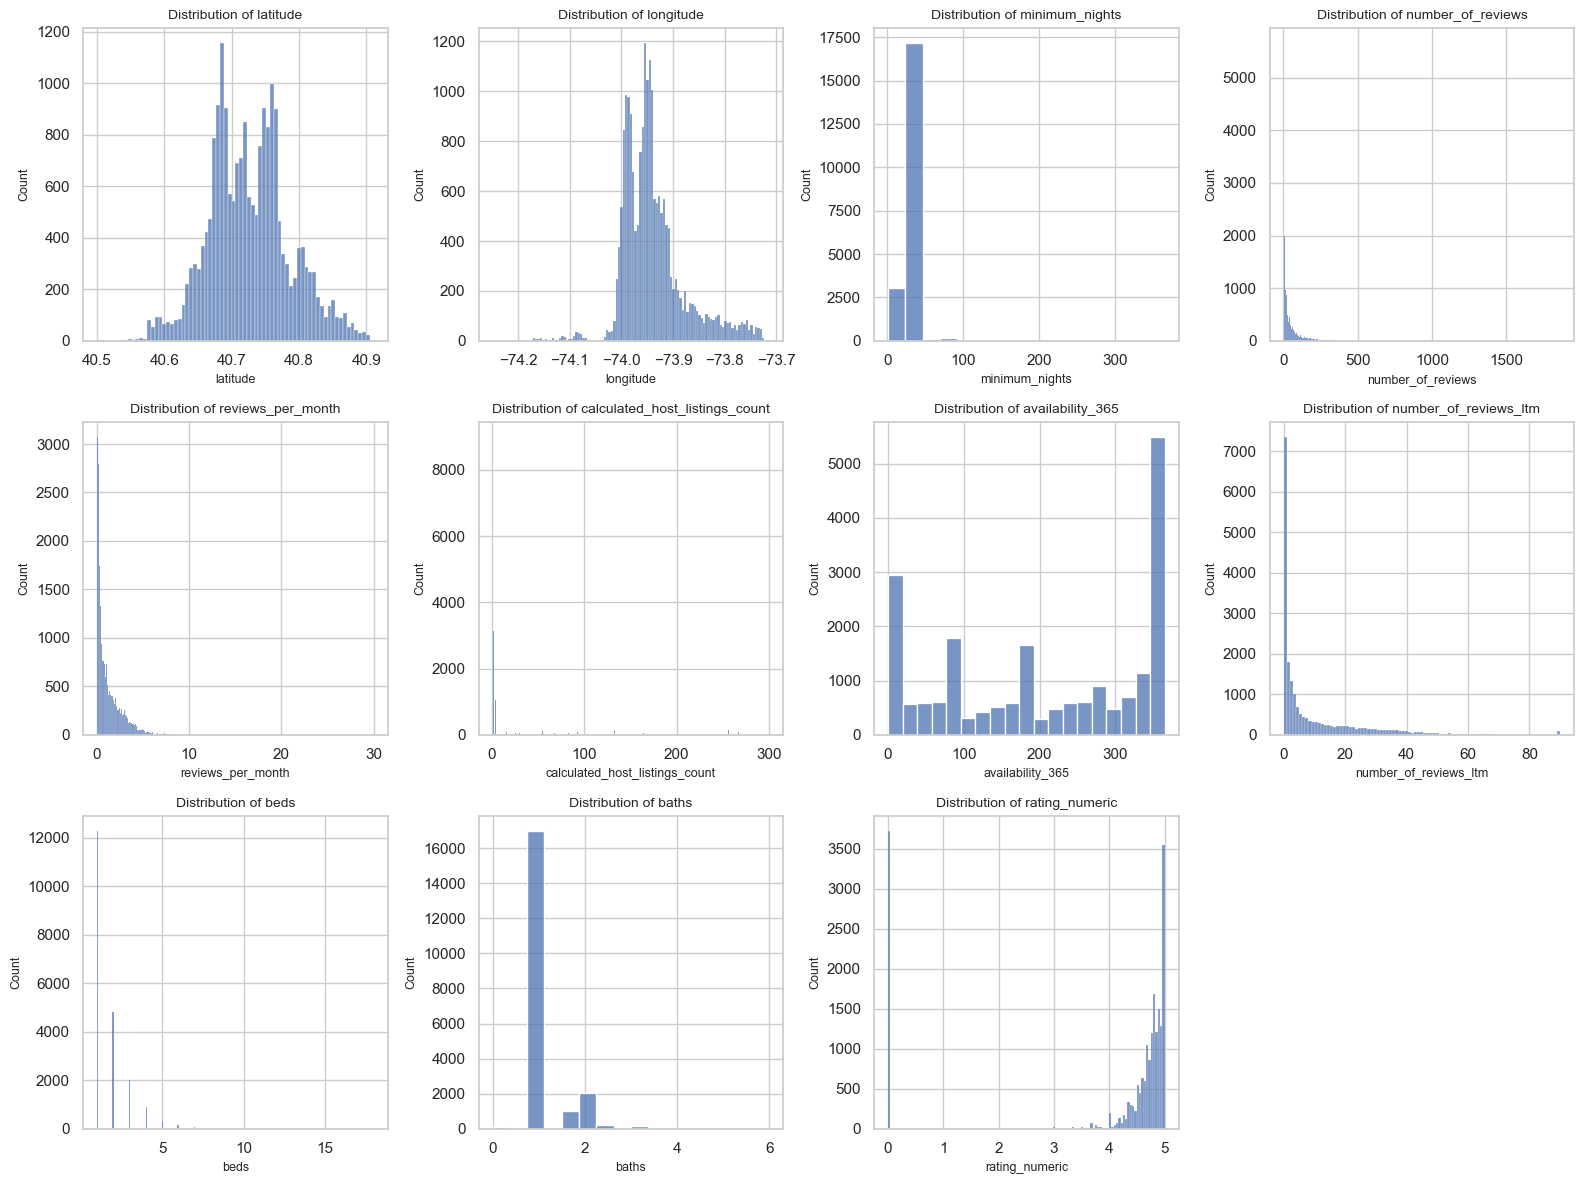

In [36]:
# Numeric columns to plot (excluding price and price_log)
num_to_plot = [
    'latitude',
    'longitude',
    'minimum_nights',
    'number_of_reviews',
    'reviews_per_month',
    'calculated_host_listings_count',
    'availability_365',
    'number_of_reviews_ltm',
    'beds',
    'baths',
    'rating_numeric'
]

n_plots = len(num_to_plot)
n_cols = 4
n_rows = int(np.ceil(n_plots / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 12))
axes = axes.flatten()

for ax, col in zip(axes, num_to_plot):
    sns.histplot(data=df, x=col, ax=ax)
    ax.set_title(f"Distribution of {col}", fontsize=10)
    ax.set_xlabel(col, fontsize=9)
    ax.set_ylabel("Count", fontsize=9)

for j in range(len(num_to_plot), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

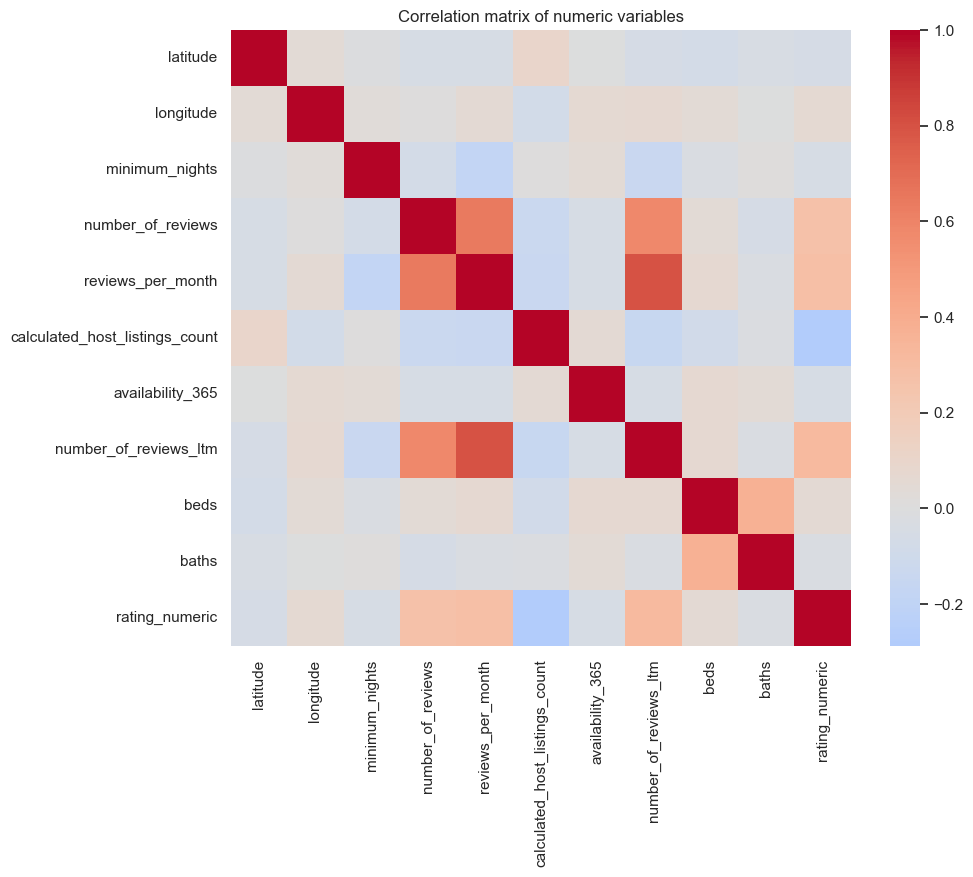

In [37]:
# Correlation matrix for numeric variables - looks fine, not so many higly correlated variables
plt.figure(figsize=(10, 8))
corr = df[num_to_plot].corr()
sns.heatmap(corr, annot=False, cmap="coolwarm", center=0)
plt.title("Correlation matrix of numeric variables")
plt.show()


### Exploratory Data Analysis

The exploratory data analysis revealed that most numeric variables exhibit highly skewed distributions, with strong right tails and the presence of extreme values. In particular, the price variable showed substantial skewness, motivating the use of a logarithmic transformation to stabilize variance and improve model performance. Other numeric features, such as review-related variables and availability measures, also displayed heavy-tailed behavior, while geographic coordinates followed compact and well-defined spatial ranges.

Visualizations including histograms, boxplots, and scatter plots highlighted clear nonlinear relationships between price and key predictors such as location, room type, and property size. Listings located in central neighborhoods and those offering entire homes or apartments tended to command higher prices, while private and shared rooms were generally cheaper.

Categorical variables showed uneven distributions, with certain categories (e.g. room type and neighborhood group) dominating the dataset. Rare categories were therefore grouped during preprocessing to reduce sparsity and improve generalization. Overall, the EDA indicated that Airbnb pricing in New York City is driven by a combination of spatial effects, property characteristics, and demand-related signals, resulting in a complex and nonlinear structure that informed the choice of tree-based ensemble models in later stages of the project.

### Data preprocessing

Prior to model training, several preprocessing steps were applied to ensure data quality and reproducibility. Numeric and categorical variables were identified explicitly and handled separately.

Categorical variables were encoded using one-hot encoding. A logarithmic transformation of the target variable was applied. Models were trained using the log-transformed price, while evaluation metrics were reported in the original price scale to preserve interpretability.




In [38]:
# Checking missing values again
print("\nMissing values after transformations:")
print(df.isna().sum())


Missing values after transformations:
neighbourhood_group               0
neighbourhood                     0
latitude                          0
longitude                         0
room_type                         0
price                             0
minimum_nights                    0
number_of_reviews                 0
reviews_per_month                 0
calculated_host_listings_count    0
availability_365                  0
number_of_reviews_ltm             0
license                           0
bedrooms                          0
beds                              0
baths                             0
price_log                         0
rating_numeric                    0
dtype: int64


In [39]:
# Split into features X and targets y (raw) and y_log (log-transformed)
y = df["price"]
y_log = df["price_log"]
# Removing both target variables from feature matrix
X = df.drop(columns=["price", "price_log"])
print("\nFeature matrix shape:", X.shape)
print("Target vector (raw price) shape:", y.shape)
print("Target vector (log price) shape:", y_log.shape)

# Identifing categorical and numeric columns - final ones
categorical_cols = X.select_dtypes(include=["object"]).columns.tolist()
numeric_cols = X.select_dtypes(exclude=["object"]).columns.tolist()
print("\nCategorical columns:", categorical_cols)
print("Numeric columns:", numeric_cols)

# One-hot encoding for categorical variables
X_encoded = pd.get_dummies(X, columns=categorical_cols, drop_first=True)
print("\nShape after one-hot encoding:", X_encoded.shape)

#  Train-test split
idx_train, idx_test = train_test_split(
    df.index,
    test_size=0.2,
    random_state=RANDOM_STATE
)

X_train = X_encoded.loc[idx_train]
X_test  = X_encoded.loc[idx_test]

y_train = y.loc[idx_train]
y_test  = y.loc[idx_test]

y_train_log = y_log.loc[idx_train]
y_test_log  = y_log.loc[idx_test]

print("\nTrain shapes:", X_train.shape, y_train_log.shape)
print("Test shapes:", X_test.shape, y_test_log.shape)


Feature matrix shape: (20654, 16)
Target vector (raw price) shape: (20654,)
Target vector (log price) shape: (20654,)

Categorical columns: ['neighbourhood_group', 'neighbourhood', 'room_type', 'license']
Numeric columns: ['latitude', 'longitude', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365', 'number_of_reviews_ltm', 'bedrooms', 'beds', 'baths', 'rating_numeric']

Shape after one-hot encoding: (20654, 145)

Train shapes: (16523, 145) (16523,)
Test shapes: (4131, 145) (4131,)


### Models and tuning strategy

Multiple supervised regression models were evaluated, ranging from simple baseline approaches to more advanced tree-based ensemble methods. The modeling pipeline began with a baseline mean predictor, followed by Random Forest as a bagging-based model, and XGBoost as a gradient boosting approach. This selection enables a structured comparison between classical ensemble techniques and more expressive boosting models capable of capturing complex nonlinear relationships.

For each model, hyperparameters were tuned using either grid search with cross-validation or out-of-bag evaluation, depending on the algorithm. The tuning process was designed to balance predictive performance and computational efficiency, with parameter grids gradually refined to ensure feasibility on a standard laptop. Model selection was primarily based on RMSE measured in the original price scale, complemented by MAE and R² to provide a comprehensive assessment of predictive accuracy and generalization performance.

In [40]:

#  Evaluation utilities

def regression_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)

    return {
        "mse": mse,
        "rmse": rmse,
        "mae": mae,
        "r2": r2
    }

def regression_metrics_from_log(y_true_log, y_pred_log):
    # Back-transform from log scale to original price scale
    y_true = np.expm1(y_true_log)
    y_pred = np.expm1(y_pred_log)

    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)

    return {
        "mse": mse,
        "rmse": rmse,
        "mae": mae,
        "r2": r2
    }

def print_regression_metrics(name, metrics_dict):
    print(f"\n{name} metrics:")
    print(f"  MSE  : {metrics_dict['mse']:.2f}")
    print(f"  RMSE : {metrics_dict['rmse']:.2f}")
    print(f"  MAE  : {metrics_dict['mae']:.2f}")
    print(f"  R^2  : {metrics_dict['r2']:.4f}")


In [41]:
#  Baseline model (log-price)  - the worst result

baseline_log = DummyRegressor(strategy="mean")
baseline_log.fit(X_train, y_train_log)

# Predictions in log scale
y_pred_baseline_train_log = baseline_log.predict(X_train)
y_pred_baseline_test_log = baseline_log.predict(X_test)

# Evaluation in original price scale (USD)
baseline_train_metrics = regression_metrics_from_log(
    y_train_log, y_pred_baseline_train_log
)
baseline_test_metrics = regression_metrics_from_log(
    y_test_log, y_pred_baseline_test_log
)

print_regression_metrics("Baseline (mean predictor, log-price) - train", baseline_train_metrics)
print_regression_metrics("Baseline (mean predictor, log-price) - test", baseline_test_metrics)



Baseline (mean predictor, log-price) - train metrics:
  MSE  : 22299.44
  RMSE : 149.33
  MAE  : 85.44
  R^2  : -0.0641

Baseline (mean predictor, log-price) - test metrics:
  MSE  : 19513.92
  RMSE : 139.69
  MAE  : 82.87
  R^2  : -0.0605


In [42]:
# Random Forest (Bagging + OOB) - looking for optimal parameters
def eval_rf_config_log(n_estimators, max_features):
    model = RandomForestRegressor(
        n_estimators=n_estimators,
        bootstrap=True,
        oob_score=True,
        n_jobs=-1,
        random_state=RANDOM_STATE,
        max_depth=None,
        min_samples_leaf=1,
        min_samples_split=2,
        max_features=max_features
    )

    # Fit on log-price
    model.fit(X_train, y_train_log)

    # OOB evaluation (log -> USD)
    oob_pred_log = model.oob_prediction_
    mask = ~np.isnan(oob_pred_log)

    y_oob_true = np.expm1(y_train_log[mask])
    y_oob_pred = np.expm1(oob_pred_log[mask])

    oob_rmse = float(np.sqrt(mean_squared_error(y_oob_true, y_oob_pred)))
    oob_r2 = float(model.oob_score_)

    # Train / test evaluation
    y_pred_train_log = model.predict(X_train)
    y_pred_test_log = model.predict(X_test)

    y_train_true = np.expm1(y_train_log)
    y_test_true = np.expm1(y_test_log)

    y_pred_train = np.expm1(y_pred_train_log)
    y_pred_test = np.expm1(y_pred_test_log)

    train_rmse = float(np.sqrt(mean_squared_error(y_train_true, y_pred_train)))
    train_r2 = float(r2_score(y_train_true, y_pred_train))

    test_rmse = float(np.sqrt(mean_squared_error(y_test_true, y_pred_test)))
    test_mae = float(mean_absolute_error(y_test_true, y_pred_test))
    test_r2 = float(r2_score(y_test_true, y_pred_test))

    return {
        "n_estimators": n_estimators,
        "max_features": max_features,
        "max_depth": None,
        "min_samples_leaf": 1,
        "min_samples_split": 2,
        "oob_r2": oob_r2,
        "oob_rmse": oob_rmse,
        "train_rmse": train_rmse,
        "train_r2": train_r2,
        "test_rmse": test_rmse,
        "test_mae": test_mae,
        "test_r2": test_r2
    }



n_estimators_grid = [200,400,600]
max_features_grid = [0.35, 0.45, 0.6, 0.7]

results = []
total = len(n_estimators_grid) * len(max_features_grid)
i = 1

for n_est in n_estimators_grid:
    for mf in max_features_grid:
        print(f"Running config {i}/{total}: n_estimators={n_est}, max_features={mf}")
        res = eval_rf_config_log(n_est, mf)
        results.append(res)
        i += 1

results_df = pd.DataFrame(results)

# Diagnostics
results_df["gap_rmse_train_test"] = results_df["test_rmse"] - results_df["train_rmse"]
results_df["gap_r2_train_test"] = results_df["train_r2"] - results_df["test_r2"]
results_df["gap_r2_oob_test"] = results_df["oob_r2"] - results_df["test_r2"]

# Sorting by best test RMSE, then OOB RMSE
results_df = results_df.sort_values(
    by=["test_rmse", "oob_rmse"]
).reset_index(drop=True)

print("\nTop configurations by test RMSE:")
display(results_df.head(5))



Running config 1/12: n_estimators=200, max_features=0.35
Running config 2/12: n_estimators=200, max_features=0.45
Running config 3/12: n_estimators=200, max_features=0.6
Running config 4/12: n_estimators=200, max_features=0.7
Running config 5/12: n_estimators=400, max_features=0.35
Running config 6/12: n_estimators=400, max_features=0.45
Running config 7/12: n_estimators=400, max_features=0.6
Running config 8/12: n_estimators=400, max_features=0.7
Running config 9/12: n_estimators=600, max_features=0.35
Running config 10/12: n_estimators=600, max_features=0.45
Running config 11/12: n_estimators=600, max_features=0.6
Running config 12/12: n_estimators=600, max_features=0.7

Top configurations by test RMSE:


,n_estimators,max_features,max_depth,min_samples_leaf,min_samples_split,oob_r2,oob_rmse,train_rmse,train_r2,test_rmse,test_mae,test_r2,gap_rmse_train_test,gap_r2_train_test,gap_r2_oob_test
0,200,0.45,None,1,2,0.662952,97.228918,46.061686,0.898753,92.667436,49.697942,0.533327,46.605750,0.365427,0.129626
1,400,0.45,None,1,2,0.665754,96.851353,45.838219,0.899733,92.698507,49.749955,0.533014,46.860288,0.366720,0.132741
2,400,0.35,None,1,2,0.665820,97.301304,46.126612,0.898468,92.766629,49.592845,0.532327,46.640017,0.366141,0.133493
3,600,0.35,None,1,2,0.666988,97.132631,46.012930,0.898968,92.807828,49.577733,0.531911,46.794898,0.367056,0.135076
4,600,0.45,None,1,2,0.666131,96.873599,45.881918,0.899542,92.807841,49.717253,0.531911,46.925923,0.367631,0.134219


In [43]:
# Random Forest as Bagging of Decision Trees - final parameters
rf_bagging_log = RandomForestRegressor(
    n_estimators=200,
    bootstrap=True,
    oob_score=True,
    n_jobs=-1,
    random_state=RANDOM_STATE,
    max_features=0.45,
    min_samples_leaf=1,
    min_samples_split=2
)

print("Fitting RandomForestRegressor (bagging) with OOB enabled on log-price...")
rf_bagging_log.fit(X_train, y_train_log)

print("\nKey settings:")
print("  bootstrap (sampling with replacement):", rf_bagging_log.bootstrap)
print("  oob_score enabled:", rf_bagging_log.oob_score)

print("\nOOB R^2 score (log-price):", rf_bagging_log.oob_score_)

# Predictions (log -> USD)
y_pred_train_log = rf_bagging_log.predict(X_train)
y_pred_test_log = rf_bagging_log.predict(X_test)

train_metrics = regression_metrics_from_log(y_train_log, y_pred_train_log)
test_metrics = regression_metrics_from_log(y_test_log, y_pred_test_log)

print_regression_metrics("RandomForest (Bagging, log-price) - TRAIN", train_metrics)
print_regression_metrics("RandomForest (Bagging, log-price) - TEST", test_metrics)


Fitting RandomForestRegressor (bagging) with OOB enabled on log-price...

Key settings:
  bootstrap (sampling with replacement): True
  oob_score enabled: True

OOB R^2 score (log-price): 0.6629524875403832

RandomForest (Bagging, log-price) - TRAIN metrics:
  MSE  : 2121.68
  RMSE : 46.06
  MAE  : 20.61
  R^2  : 0.8988

RandomForest (Bagging, log-price) - TEST metrics:
  MSE  : 8587.25
  RMSE : 92.67
  MAE  : 49.70
  R^2  : 0.5333


In [44]:
# Classical Boosting – Gradient Boosting Regressor
from sklearn.ensemble import GradientBoostingRegressor

gbr = GradientBoostingRegressor(
    loss="squared_error",     
    learning_rate=0.05,       
    n_estimators=300,         
    max_depth=3,              
    subsample=0.8,            
    random_state=RANDOM_STATE
)

print("Fitting GradientBoostingRegressor (log-price)...")
gbr.fit(X_train, y_train_log)


# Predictions 
y_pred_train_log = gbr.predict(X_train)
y_pred_test_log = gbr.predict(X_test)

# Evaluate in original price scale (USD)
gbr_train_metrics = regression_metrics_from_log(
    y_train_log, y_pred_train_log
)
gbr_test_metrics = regression_metrics_from_log(
    y_test_log, y_pred_test_log
)

print_regression_metrics(
    "Gradient Boosting (log-price) - TRAIN",
    gbr_train_metrics
)
print_regression_metrics(
    "Gradient Boosting (log-price) - TEST",
    gbr_test_metrics
)


Fitting GradientBoostingRegressor (log-price)...

Gradient Boosting (log-price) - TRAIN metrics:
  MSE  : 10024.77
  RMSE : 100.12
  MAE  : 53.24
  R^2  : 0.5216

Gradient Boosting (log-price) - TEST metrics:
  MSE  : 9441.34
  RMSE : 97.17
  MAE  : 52.64
  R^2  : 0.4869


In [58]:
# XGBoost Regressor (log-price) + hyperparameter search (already after few tries, most promising parameters were choosen)
xgb_base = xgb.XGBRegressor(
    objective="reg:squarederror",
    random_state=RANDOM_STATE,
    n_jobs=-1,
    tree_method="hist"
)


xgb_param_grid = {
    "n_estimators": [725,750],
    "max_depth": [8,9],
    "learning_rate": [0.023,0.024],
    "subsample": [0.82,0.825],
    "colsample_bytree": [0.65]
}

# MSE optimisation
xgb_grid_search = GridSearchCV(
    estimator=xgb_base,
    param_grid=xgb_param_grid,
    cv=3,
    scoring="neg_mean_squared_error",
    n_jobs=-1,
    verbose=1
)

print("\nFitting XGBRegressor with GridSearchCV (target = log-price)...")
xgb_grid_search.fit(X_train, y_train_log)

print("\nBest parameters for XGBRegressor (log-price):")
print(xgb_grid_search.best_params_)

best_xgb = xgb_grid_search.best_estimator_

# Predictions
y_pred_train_log = best_xgb.predict(X_train)
y_pred_test_log = best_xgb.predict(X_test)

#Evaluations
xgb_train_metrics = regression_metrics_from_log(y_train_log, y_pred_train_log)
xgb_test_metrics = regression_metrics_from_log(y_test_log, y_pred_test_log)

print_regression_metrics("XGBoost (log-price) - TRAIN", xgb_train_metrics)
print_regression_metrics("XGBoost (log-price) - TEST", xgb_test_metrics)



Fitting XGBRegressor with GridSearchCV (target = log-price)...
Fitting 3 folds for each of 16 candidates, totalling 48 fits

Best parameters for XGBRegressor (log-price):
{'colsample_bytree': 0.65, 'learning_rate': 0.023, 'max_depth': 9, 'n_estimators': 750, 'subsample': 0.825}

XGBoost (log-price) - TRAIN metrics:
  MSE  : 2771.65
  RMSE : 52.65
  MAE  : 26.97
  R^2  : 0.8677

XGBoost (log-price) - TEST metrics:
  MSE  : 8190.50
  RMSE : 90.50
  MAE  : 48.53
  R^2  : 0.5549


In [46]:
# XGBoost Regressor (log-price) + final parameters

xgb_base = xgb.XGBRegressor(
    objective="reg:squarederror",
    random_state=RANDOM_STATE,
    n_jobs=-1,
    tree_method="hist"
)

# final parameters
xgb_param_grid = {
    "n_estimators": [750],
    "max_depth": [9],
    "learning_rate": [0.023],
    "subsample": [0.825],
    "colsample_bytree": [0.65]
}


xgb_grid_search = GridSearchCV(
    estimator=xgb_base,
    param_grid=xgb_param_grid,
    cv=3,
    scoring="neg_mean_squared_error",
    n_jobs=-1,
    verbose=1
)

print("\nFitting XGBRegressor with GridSearchCV (target = log-price)...")
xgb_grid_search.fit(X_train, y_train_log)

print("\nBest parameters for XGBRegressor (log-price):")
print(xgb_grid_search.best_params_)

best_xgb = xgb_grid_search.best_estimator_

# Predictions 
y_pred_train_log = best_xgb.predict(X_train)
y_pred_test_log = best_xgb.predict(X_test)

# Evaluations
xgb_train_metrics = regression_metrics_from_log(y_train_log, y_pred_train_log)
xgb_test_metrics = regression_metrics_from_log(y_test_log, y_pred_test_log)

print_regression_metrics("XGBoost (log-price) - TRAIN", xgb_train_metrics)
print_regression_metrics("XGBoost (log-price) - TEST", xgb_test_metrics)



Fitting XGBRegressor with GridSearchCV (target = log-price)...
Fitting 3 folds for each of 1 candidates, totalling 3 fits

Best parameters for XGBRegressor (log-price):
{'colsample_bytree': 0.65, 'learning_rate': 0.023, 'max_depth': 9, 'n_estimators': 750, 'subsample': 0.825}

XGBoost (log-price) - TRAIN metrics:
  MSE  : 2771.65
  RMSE : 52.65
  MAE  : 26.97
  R^2  : 0.8677

XGBoost (log-price) - TEST metrics:
  MSE  : 8190.50
  RMSE : 90.50
  MAE  : 48.53
  R^2  : 0.5549


In [47]:
# XGBoost with Early Stopping using xgb.train() to find optimal number of estiamtors


dtrain = xgb.DMatrix(X_train, label=y_train_log)
dtest  = xgb.DMatrix(X_test,  label=y_test_log)

# Defining parameters 
params = {
    "objective": "reg:squarederror",
    "eval_metric": "rmse",
    "max_depth": 9,
    "eta": 0.023,                 
    "subsample": 0.825,
    "colsample_bytree": 0.65,
    "seed": RANDOM_STATE
}

# Training with early stopping
print("Training XGBoost with early stopping (log-price)...")

xgb_es_model = xgb.train(
    params=params,
    dtrain=dtrain,
    num_boost_round=2000,                
    evals=[(dtrain, "train"), (dtest, "valid")],
    early_stopping_rounds=50,
    verbose_eval=False
)

print(f"Best iteration (trees used): {xgb_es_model.best_iteration + 1}")


# Evaluation
# Predictions in log-space
y_pred_train_log = xgb_es_model.predict(dtrain)
y_pred_test_log  = xgb_es_model.predict(dtest)

# Evaluate in original price scale (USD)
xgb_es_train_metrics = regression_metrics_from_log(
    y_train_log, y_pred_train_log
)
xgb_es_test_metrics = regression_metrics_from_log(
    y_test_log, y_pred_test_log
)

print_regression_metrics(
    "XGBoost with Early Stopping (log-price) - TRAIN",
    xgb_es_train_metrics
)
print_regression_metrics(
    "XGBoost with Early Stopping (log-price) - TEST",
    xgb_es_test_metrics
)


Training XGBoost with early stopping (log-price)...
Best iteration (trees used): 909

XGBoost with Early Stopping (log-price) - TRAIN metrics:
  MSE  : 2202.60
  RMSE : 46.93
  MAE  : 23.93
  R^2  : 0.8949

XGBoost with Early Stopping (log-price) - TEST metrics:
  MSE  : 8185.75
  RMSE : 90.48
  MAE  : 48.54
  R^2  : 0.5551


In [48]:
# Ensemble Learning (Averaging) - we combined 2 models, the best Random Forest and the best XGBoost

# Base models with winning hyperparameters

rf_final_log = RandomForestRegressor(
    n_estimators=200,          
    max_features=0.45,         
    min_samples_split=2,
    min_samples_leaf=1,
    max_depth=None,
    bootstrap=True,
    oob_score=False,          
    n_jobs=-1,
    random_state=RANDOM_STATE
)

xgb_final_log = xgb.XGBRegressor(
    objective="reg:squarederror",
    random_state=RANDOM_STATE,
    n_jobs=-1,
    tree_method="hist",
    n_estimators=909,        
    max_depth=9,               
    learning_rate=0.023,        
    subsample=0.825,             
    colsample_bytree=0.65       
)


ensemble_log = VotingRegressor(
    estimators=[
        ("rf", rf_final_log),
        ("xgb", xgb_final_log)
    ],
    weights=None 
)

print("Fitting Ensemble (RF + XGB) on log-price...")
ensemble_log.fit(X_train, y_train_log)

# Predictions in log-space
y_pred_train_log = ensemble_log.predict(X_train)
y_pred_test_log = ensemble_log.predict(X_test)

# Evaluate in original price scale 
ens_train_metrics = regression_metrics_from_log(y_train_log, y_pred_train_log)
ens_test_metrics = regression_metrics_from_log(y_test_log, y_pred_test_log)

print_regression_metrics("Ensemble (RF + XGB, log-price) - TRAIN", ens_train_metrics)
print_regression_metrics("Ensemble (RF + XGB, log-price) - TEST", ens_test_metrics)


Fitting Ensemble (RF + XGB) on log-price...

Ensemble (RF + XGB, log-price) - TRAIN metrics:
  MSE  : 2154.08
  RMSE : 46.41
  MAE  : 22.35
  R^2  : 0.8972

Ensemble (RF + XGB, log-price) - TEST metrics:
  MSE  : 8279.90
  RMSE : 90.99
  MAE  : 48.62
  R^2  : 0.5500


In [49]:
# Final comparison table of models

comparison_table = pd.DataFrame([
    {
        "Model": "Baseline (Mean Predictor)",
        "Test RMSE": baseline_test_metrics["rmse"],
        "Test R2": baseline_test_metrics["r2"],
        "Notes": "Naive baseline"
    },
    {
        "Model": "Random Forest (log-price)",
        "Test RMSE": test_metrics["rmse"],
        "Test R2": test_metrics["r2"],
        "Notes": "Bagging + OOB validation"
    },
    {
        "Model": "Gradient Boosting (log-price)",
        "Test RMSE": gbr_test_metrics["rmse"],
        "Test R2": gbr_test_metrics["r2"],
        "Notes": "Classical boosting"
    },
    {
        "Model": "XGBoost + Early Stopping (log-price)",
        "Test RMSE": xgb_es_test_metrics["rmse"],
        "Test R2": xgb_es_test_metrics["r2"],
        "Notes": "FINAL MODEL"
    },
    {
        "Model": "Ensemble (RF + XGB)",
        "Test RMSE": ens_test_metrics["rmse"],
        "Test R2": ens_test_metrics["r2"],
        "Notes": "No improvement over XGB"
    }
])

# Sort by RMSE 
comparison_table = comparison_table.sort_values(
    by="Test RMSE"
).reset_index(drop=True)

comparison_table


,Model,Test RMSE,Test R2,Notes
0,XGBoost + Early Stopping (log-price),90.475141,0.555146,FINAL MODEL
1,Ensemble (RF + XGB),90.993964,0.550030,No improvement over XGB
2,Random Forest (log-price),92.667436,0.533327,Bagging + OOB validation
3,Gradient Boosting (log-price),97.166533,0.486912,Classical boosting
4,Baseline (Mean Predictor),139.692215,-0.060482,Naive baseline


### Model comparison and initial results

The table summarizes the predictive performance of the evaluated regression models, all trained on the full feature set using tuned hyperparameters. Model performance was primarily assessed using RMSE and R² on the test set, both reported in the original price scale for interpretability.

XGBoost with early stopping achieves the best overall performance, yielding the lowest test RMSE (approximately 90.5 USD) and the highest R² (0.56) among the evaluated models. The use of early stopping effectively controls model complexity and reduces overfitting, allowing the model to generalize well to unseen data. For this reason, XGBoost with early stopping was selected as the final model.

The ensemble model combining Random Forest and XGBoost does not improve upon the standalone XGBoost results. While ensemble averaging slightly stabilizes predictions, it fails to reduce the prediction error further, indicating that the two models capture largely overlapping patterns in the data.

The Random Forest model, trained using bagging with out-of-bag validation, performs reasonably well but exhibits a higher test RMSE and lower R² compared to XGBoost. This suggests that while bagging reduces variance, it is less effective than boosting at capturing complex nonlinear interactions present in the pricing data.

The classical Gradient Boosting model shows weaker performance, with a noticeably higher RMSE and lower R². This indicates limited flexibility compared to XGBoost, which benefits from more advanced regularization and optimization mechanisms.

Finally, the baseline mean predictor performs substantially worse than all machine learning models, yielding a negative R² value. This confirms that the models are learning meaningful relationships beyond simply predicting the average price.

Overall, the comparison highlights the importance of boosting-based methods for modeling Airbnb prices in New York City and motivates the selection of XGBoost with early stopping as the final predictive model.

### THE WINNER

In [50]:
# FINAL MODEL: XGBoost with Early Stopping 

dtrain = xgb.DMatrix(X_train, label=y_train_log)
dtest  = xgb.DMatrix(X_test,  label=y_test_log)

# Final hyperparameters (selected after tuning)
final_xgb_params = {
    "objective": "reg:squarederror",
    "eval_metric": "rmse",
    "max_depth": 9,
    "eta": 0.023,                 
    "subsample": 0.825,
    "colsample_bytree": 0.65,
    "seed": RANDOM_STATE
}

final_xgb_model = xgb.train(
    params=final_xgb_params,
    dtrain=dtrain,
    num_boost_round=2000,          
    evals=[(dtrain, "train"), (dtest, "valid")],
    early_stopping_rounds=50,
    verbose_eval=False
)

print("Training FINAL XGBoost model with early stopping (log-price)...")
print(f"Best iteration (trees used): {final_xgb_model.best_iteration + 1}")


# Final evaluation

# Predictions in log-space
y_pred_train_log = final_xgb_model.predict(dtrain)
y_pred_test_log  = final_xgb_model.predict(dtest)

# Evaluation in original price scale (USD)
final_xgb_train_metrics = regression_metrics_from_log(
    y_train_log, y_pred_train_log
)
final_xgb_test_metrics = regression_metrics_from_log(
    y_test_log, y_pred_test_log
)

print_regression_metrics(
    "FINAL XGBoost (log-price) - TRAIN",
    final_xgb_train_metrics
)
print_regression_metrics(
    "FINAL XGBoost (log-price) - TEST",
    final_xgb_test_metrics
)


Training FINAL XGBoost model with early stopping (log-price)...
Best iteration (trees used): 909

FINAL XGBoost (log-price) - TRAIN metrics:
  MSE  : 2202.60
  RMSE : 46.93
  MAE  : 23.93
  R^2  : 0.8949

FINAL XGBoost (log-price) - TEST metrics:
  MSE  : 8185.75
  RMSE : 90.48
  MAE  : 48.54
  R^2  : 0.5551


Top 15 most important features (by gain):


,feature,importance_gain,importance_gain_norm
141,room_type_Private room,14.888094,0.188287
142,room_type_Shared room,5.458369,0.069031
143,license_No License,4.186059,0.052940
8,bedrooms,2.632802,0.033297
10,baths,2.378443,0.030080
13,neighbourhood_group_Manhattan,1.987735,0.025139
9,beds,1.288402,0.016294
92,neighbourhood_Midtown,0.978944,0.012381
14,neighbourhood_group_Queens,0.921271,0.011651
5,calculated_host_listings_count,0.818131,0.010347


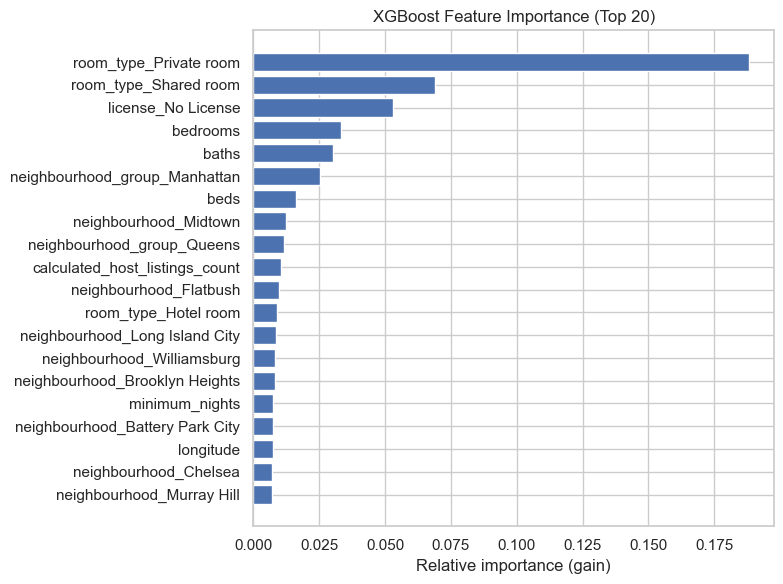

In [51]:
# Feature importance for FINAL XGBoost model

# Geting feature importance (gain-based)
importance_dict = final_xgb_model.get_score(importance_type="gain")

importance_df = (
    pd.DataFrame(
        importance_dict.items(),
        columns=["feature", "importance_gain"]
    )
    .sort_values(by="importance_gain", ascending=False)
)

importance_df["importance_gain_norm"] = (
    importance_df["importance_gain"] / importance_df["importance_gain"].sum()
)

# Display top features
print("Top 15 most important features (by gain):")
display(importance_df.head(15))

# Ploting feature importance
plt.figure(figsize=(8, 6))
plt.barh(
    importance_df.head(20)["feature"][::-1],
    importance_df.head(20)["importance_gain_norm"][::-1]
)
plt.xlabel("Relative importance (gain)")
plt.title("XGBoost Feature Importance (Top 20)")
plt.tight_layout()
plt.show()


### Feature importance summary

The feature importance analysis indicates that Airbnb prices in New York City are primarily driven by room type, property size, and regulatory and location-related factors. The strongest predictor is room type, with private and shared rooms having the largest impact on price differentiation. Variables describing property size, such as the number of bedrooms, bathrooms, and beds, also play a significant role, confirming that larger accommodations tend to command higher prices.

Location-related features, particularly neighbourhood group and specific high-demand areas such as Manhattan and Midtown, further contribute to price variation. In addition, the license status emerges as an important factor, suggesting that regulatory compliance is associated with pricing differences. Overall, the results are consistent with economic intuition and confirm that the model captures meaningful structural drivers of Airbnb pricing rather than spurious correlations.

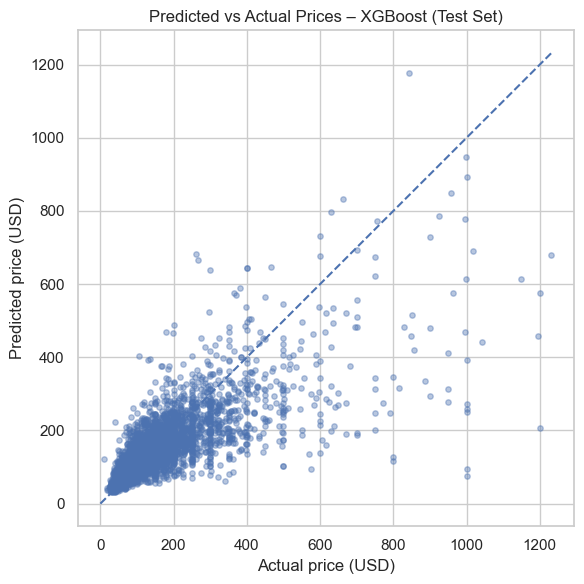

In [52]:
# Predicted vs Actual values (FINAL XGBoost model)

y_test_real = np.expm1(y_test_log)
y_pred_real = np.expm1(y_pred_test_log)

plt.figure(figsize=(6, 6))
plt.scatter(
    y_test_real,
    y_pred_real,
    alpha=0.4,
    s=15
)

max_price = max(y_test_real.max(), y_pred_real.max())
plt.plot([0, max_price], [0, max_price], linestyle="--")

plt.xlabel("Actual price (USD)")
plt.ylabel("Predicted price (USD)")
plt.title("Predicted vs Actual Prices – XGBoost (Test Set)")
plt.tight_layout()
plt.show()


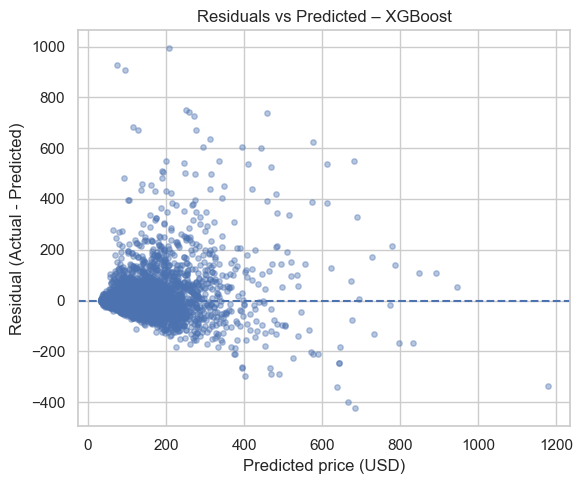

In [53]:
# Residuals vs Predicted

residuals = y_test_real - y_pred_real

plt.figure(figsize=(6, 5))
plt.scatter(
    y_pred_real,
    residuals,
    alpha=0.4,
    s=15
)

plt.axhline(0, linestyle="--")
plt.xlabel("Predicted price (USD)")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residuals vs Predicted – XGBoost")
plt.tight_layout()
plt.show()


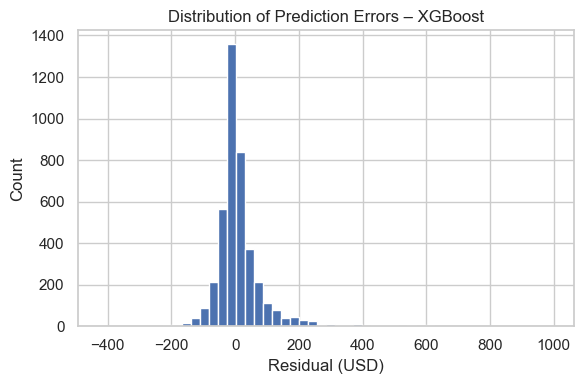

In [54]:
# Distribution of residuals

plt.figure(figsize=(6, 4))
plt.hist(residuals, bins=50)
plt.xlabel("Residual (USD)")
plt.ylabel("Count")
plt.title("Distribution of Prediction Errors – XGBoost")
plt.tight_layout()
plt.show()


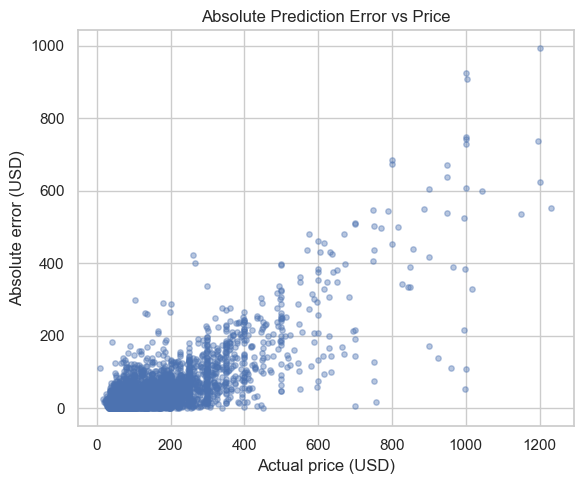

In [55]:
# Error vs actual price

plt.figure(figsize=(6, 5))
plt.scatter(
    y_test_real,
    np.abs(residuals),
    alpha=0.4,
    s=15
)

plt.xlabel("Actual price (USD)")
plt.ylabel("Absolute error (USD)")
plt.title("Absolute Prediction Error vs Price")
plt.tight_layout()
plt.show()


In [56]:
# Top 10 largest prediction errors (test set)

errors_df = pd.DataFrame({
    "actual_price": np.expm1(y_test_log),
    "predicted_price": np.expm1(y_pred_test_log)
})

errors_df["error"] = errors_df["actual_price"] - errors_df["predicted_price"]
errors_df["abs_error"] = errors_df["error"].abs()

# Sort by absolute error
top_errors = errors_df.sort_values(
    by="abs_error",
    ascending=False
).head(10)

top_errors


,actual_price,predicted_price,error,abs_error
3974,1200.0,207.132980,992.867020,992.867020
1448,1000.0,74.570076,925.429924,925.429924
6483,1002.0,93.336647,908.663353,908.663353
8104,1000.0,251.482162,748.517838,748.517838
49,1000.0,257.556396,742.443604,742.443604
5298,1195.0,458.055389,736.944611,736.944611
1460,1000.0,271.566071,728.433929,728.433929
5269,800.0,115.471214,684.528786,684.528786
2446,800.0,127.289764,672.710236,672.710236
6592,949.0,277.654449,671.345551,671.345551


In [57]:
# Features of the worst-predicted listings

top_error_indices = top_errors.index

top_error_features = X_test.loc[top_error_indices].copy()
top_error_features["actual_price"] = top_errors["actual_price"]
top_error_features["predicted_price"] = top_errors["predicted_price"]
top_error_features["abs_error"] = top_errors["abs_error"]

top_error_features


,latitude,longitude,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm,bedrooms,beds,...,neighbourhood_Woodhaven,neighbourhood_Woodside,room_type_Hotel room,room_type_Private room,room_type_Shared room,license_No License,license_OSE,actual_price,predicted_price,abs_error
3974,40.651172,-73.837426,30,6,0.34,2,365,0,1,3,...,False,False,False,False,False,True,False,1200.0,207.132980,992.867020
1448,40.713030,-73.952970,35,6,0.06,1,0,0,1,1,...,False,False,False,True,False,True,False,1000.0,74.570076,925.429924
6483,40.711580,-73.953640,365,10,0.10,1,0,0,1,2,...,False,False,False,True,False,True,False,1002.0,93.336647,908.663353
8104,40.706240,-73.953810,30,25,0.81,1,364,8,3,3,...,False,False,False,False,False,True,False,1000.0,251.482162,748.517838
49,40.792960,-73.964990,30,23,0.18,10,364,0,2,1,...,False,False,False,False,False,True,False,1000.0,257.556396,742.443604
5298,40.764360,-73.975620,7,1,1.00,16,362,1,2,2,...,False,False,False,False,False,False,False,1195.0,458.055389,736.944611
1460,40.774160,-73.985910,30,44,0.32,10,364,0,2,1,...,False,False,False,False,False,True,False,1000.0,271.566071,728.433929
5269,40.657850,-73.960680,30,4,0.04,1,0,0,2,2,...,False,False,False,False,False,True,False,800.0,115.471214,684.528786
2446,40.717159,-74.001664,3,4,2.93,1,44,4,1,1,...,False,False,False,True,False,False,False,800.0,127.289764,672.710236
6592,40.710026,-74.011360,1,4,0.18,7,364,1,1,2,...,False,False,False,True,False,False,False,949.0,277.654449,671.345551


### Error analysis
The error analysis shows that the XGBoost model performs well for the majority of typical Airbnb listings, with predictions closely aligned to actual prices in the low- and mid-price range. However, the largest prediction errors are associated with a small number of extremely expensive listings, where the model substantially underestimates true prices. These listings often represent rare and atypical cases, such as premium properties or hotel-like accommodations, which are weakly represented in the training data.

Residual plots indicate increasing error variance as prices rise, revealing heteroskedasticity that is characteristic of real-world housing and rental markets. The distribution of residuals remains centered around zero, suggesting no systematic bias toward over- or under-prediction across most observations. Inspection of the worst-predicted listings confirms that extreme prices, combined with uncommon feature combinations, are the primary drivers of large errors. Overall, these results indicate that the model generalizes well for standard listings but faces inherent limitations when predicting rare, high-end properties.

### Ethical considerations
The project considered ethical aspects related to potential bias and model misuse. Airbnb pricing data may reflect existing market inequalities, including differences across neighborhoods and regulatory status, which the model can inadvertently reinforce if used without caution. The model is intended for analytical and educational purposes and should not be applied directly to pricing decisions without human oversight. Additionally, sensitive attributes such as personal host information were excluded from modeling, reducing the risk of unfair or discriminatory outcomes.

### Reproducibility and code structure

All experiments are fully reproducible. A fixed random seed is used throughout the project, and all preprocessing, model training, and evaluation steps are implemented in a clear and modular way.

The notebook follows a logical structure from data loading and EDA through modelling and interpretation. Reusable functions are employed where appropriate, and intermediate results are explicitly reported to ensure transparency and ease of understanding.


### Summary and conclusions

This project investigated the problem of predicting Airbnb listing prices in New York City using supervised regression models. The analysis covered data preprocessing, exploratory data analysis and the evaluation of multiple machine learning models, ranging from simple baselines to advanced models such as XGBoost with early stopping . Due to the highly skewed price distribution, a logarithmic transformation of the target variable was applied, which improved model stability and generalization.

Among the evaluated models, XGBoost with early stopping achieved the best performance, delivering the lowest test RMSE and the highest R² while effectively controlling overfitting. Feature importance analysis confirmed that pricing is primarily driven by room type, property size, location, and regulatory status. Error analysis showed that the model performs well for typical listings but struggles with rare, high-priced properties, reflecting inherent limitations of the data.

Overall, the results demonstrate that modern boosting-based methods are well suited for modeling complex pricing dynamics in short-term rental markets. While the model provides accurate and interpretable predictions for the majority of listings, future improvements could include richer location features, temporal information, and external demand signals to further enhance predictive performance.

### References 
- Kaggle:New York Airbnb Open Data 2024